# Data exploration and preparation

This notebook walks through the full data pipeline, from raw pickle files on disk   to collated `NeuralBatch` tensors and provides inline visualisations at every step.

**Sections**
1. Environment & imports (setting up the required packages and paths) 
2. Dataset loading  
3. Raw data structure (visual inspection of original dataset)
4. Batch collation (how `NeuralBatches` are created and shapes visualization)
5. Signal augmentations

---
## 1. Environment & imports

In [12]:
%load_ext autoreload
%autoreload 2

In [13]:
import os
import sys
import re

# Run from repo root regardless of where the kernel was launched
REPO_ROOT = os.path.abspath(os.path.join(os.path.dirname('__file__'), '..'))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

# Load .envrc so dataset paths are available regardless of how Jupyter was launched.
# Keys already present in the environment are left untouched.

_envrc = os.path.join(REPO_ROOT, ".envrc")
if os.path.exists(_envrc):
    with open(_envrc) as _f:
        for _line in _f:
            _m = re.match(r'^export\s+(\w+)=(["\']?)(.+?)\2\s*$', _line.strip())
            if _m:
                _key, _val = _m.group(1), _m.group(3)
                if _key not in os.environ:
                    os.environ[_key] = _val
                    print(f"  set  {_key} = {_val}")
                else:
                    print(f"  skip {_key}  (already in environment)")
else:
    print(f"WARNING: .envrc not found at {_envrc}")


import numpy as np
import torch
from IPython.display import display
from torch.utils.data import DataLoader
from transformers import WhisperTokenizer

from brainwhisperer.viz import load_theme

THEME = load_theme()

TOKENIZER = WhisperTokenizer.from_pretrained(
    'openai/whisper-tiny', language='en', task='transcribe'
)

print('torch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

  skip CARD_ROOT  (already in environment)
  skip KUNZ_ROOT  (already in environment)
  skip WILLETT_ROOT  (already in environment)
  skip RNN_ARGS  (already in environment)
torch 2.11.0+cu128
CUDA available: True


---
## 2. Dataset loading

Tries **CARD** first, then **Willett**, then falls back to a synthetic batch if these datasets are not found or properly loaded, so every cell below still runs without real data.

In [14]:
from brainwhisperer.data.collate import NeuralCollator
from brainwhisperer.data.registry import get_dataset

BATCH_SIZE = 8
COLLATOR   = NeuralCollator(TOKENIZER)

ds     = None
loader = None

for dataset_name in ('card', 'willet'):
    try:
        if dataset_name == 'card':
            import brainwhisperer.data.datasets.card   # noqa — registers dataset
        else:
            import brainwhisperer.data.datasets.willett  # noqa

        ds     = get_dataset(dataset_name)(split='train')
        loader = DataLoader(ds, batch_size=BATCH_SIZE, collate_fn=COLLATOR, shuffle=True)
        print(f'Loaded {dataset_name!r} — {len(ds)} samples')
        break
    except Exception as exc:
        print(f'{dataset_name}: {exc}')

if ds is None:
    print('No real dataset found — using synthetic fallback')

Loaded 'card' — 8069 samples


In [15]:
# Quick dataset summary
if ds is not None:
    base     = ds._base
    n_days   = int(base.days.max().item()) + 1
    t_values = [np.asarray(base.neural_features[i]).shape[0] for i in range(len(base))]
    c_value  = np.asarray(base.neural_features[0]).shape[1]

    print(f'Sentences  : {len(base)}')
    print(f'Days       : {n_days}  (indices {int(base.days.min())} – {int(base.days.max())})')
    print(f'Channels C : {c_value}')
    print(f'T per sentence — min {min(t_values)}, median {int(np.median(t_values))}, max {max(t_values)}')
else:
    n_days = 20
    print('synthetic')

Sentences  : 8069
Days       : 45  (indices 0 – 44)
Channels C : 512
T per sentence — min 138, median 837, max 2475


---
## 3. Raw data structure

Datasets contain neural recording of subject(s) attempting to speak in both prompted and unstructured conversational contexts. As such, the data is divided per sentences of varying length. Multiple sentences have been recorded for each day of the study. Each sentence has the neural data associated which is a matrix of shape `[T_sentence, C]`, where `T_sentence` are the timesteps associated with the sentence and `C` is the number of recorded channels.

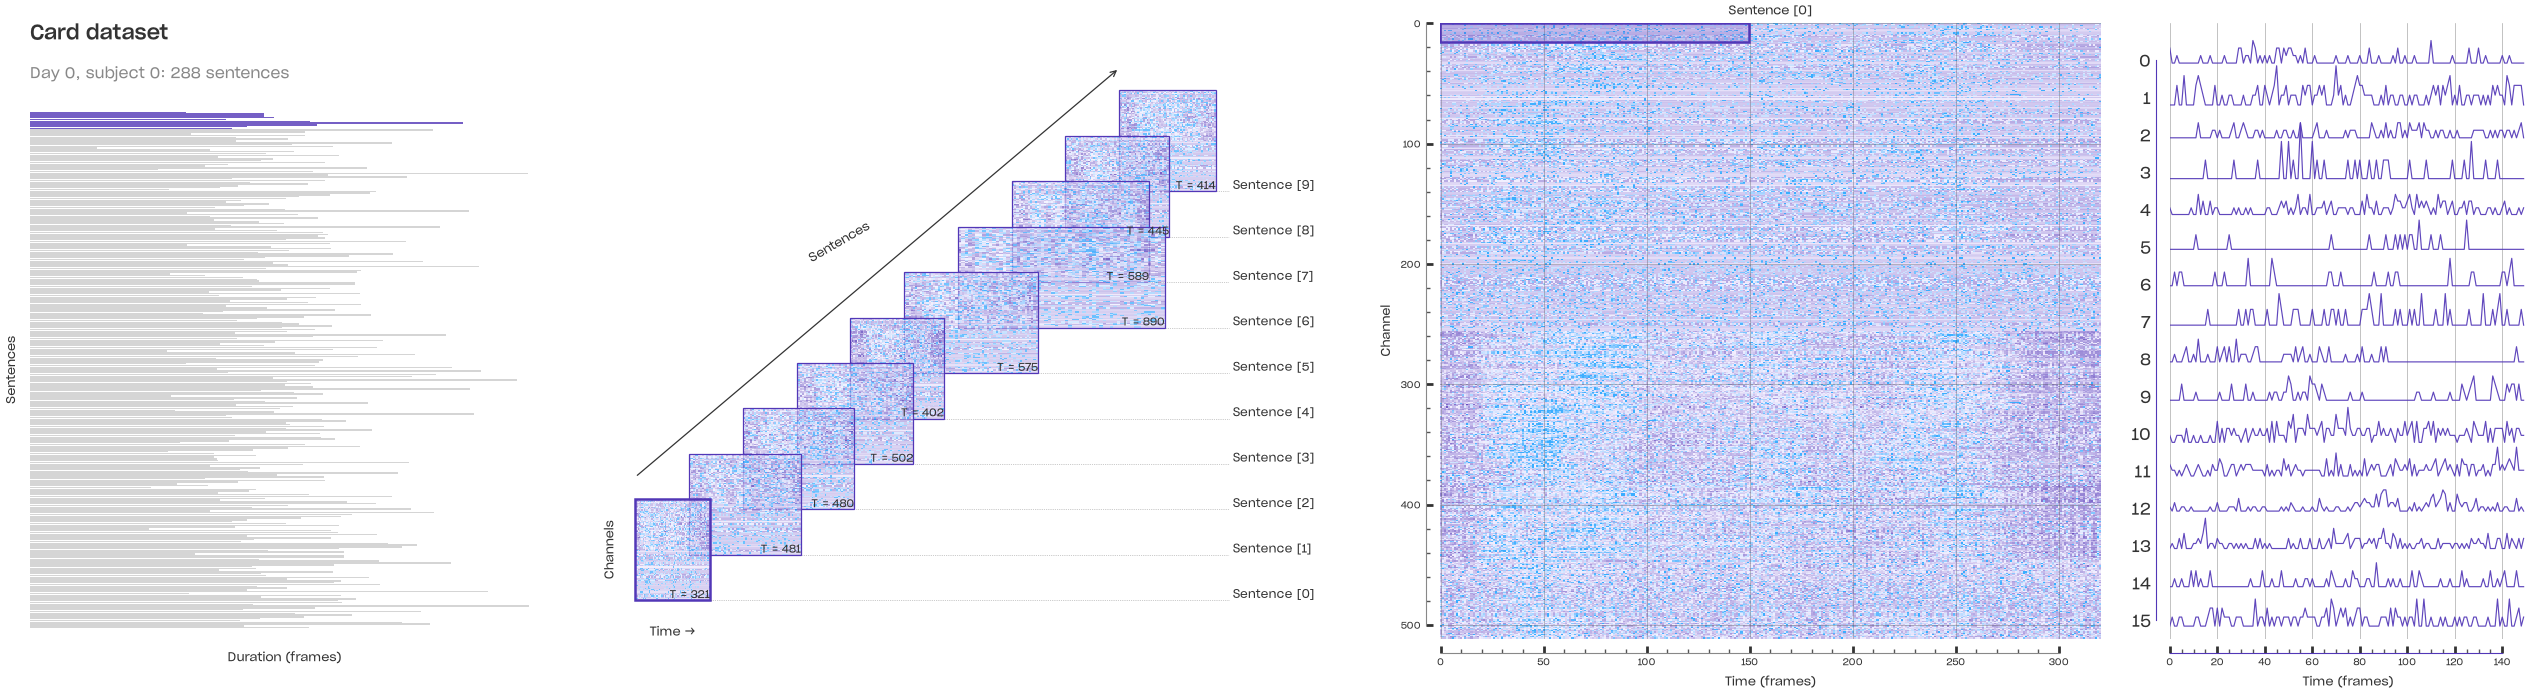

In [50]:
# ── parameters ────────────────────────────────────────────────────────────────
DAY_TO_SHOW    = 0      # which day to visualise
N_SENTENCES    = 10      # how many sentences to include in the stack
ZOOM_SENTENCE  = 0      # which sentence to zoom into (0 = front card)
ZOOM_CHANNELS  = (0, 16)    # channel range for the zoom box
ZOOM_TIME      = (0, 150)   # time frame range for the zoom box
# ──────────────────────────────────────────────────────────────────────────────

if ds is not None:
    from brainwhisperer.viz.data_pipeline import plot_dataset_structure

    with THEME:
        fig = plot_dataset_structure(
            ds,
            day           = DAY_TO_SHOW,
            n_sentences   = N_SENTENCES,
            zoom_sentence = ZOOM_SENTENCE,
            zoom_channels = ZOOM_CHANNELS,
            zoom_time     = ZOOM_TIME,
        )
    display(fig)
else:
    print('Skipped — no real dataset available')

---
## 4. Batch collation

The `NeuralCollator` receives a list of sentences forming a batch. It pads all sentences using the longest timespan (`T_max = max(T_i)`), producing a `NeuralBatch` of shape `(B, C, T_max)`. \
If training data contains the ground truth sentence labels, these are also collected within the `NeuralBatch`. 

As "metadata", `NeuralBatch` classes contain and keep track of the original length, day and subject of all sentences forming the batch.  

signals : (8, 512, 1614) torch.float32
labels  : (8, 17)
sbj_idx : [0, 0, 0, 0, 0, 0, 0, 0]
day_idx : [21, 11, 31, 5, 19, 12, 12, 23]
lengths : [1011, 817, 1086, 924, 1614, 1106, 507, 1044]


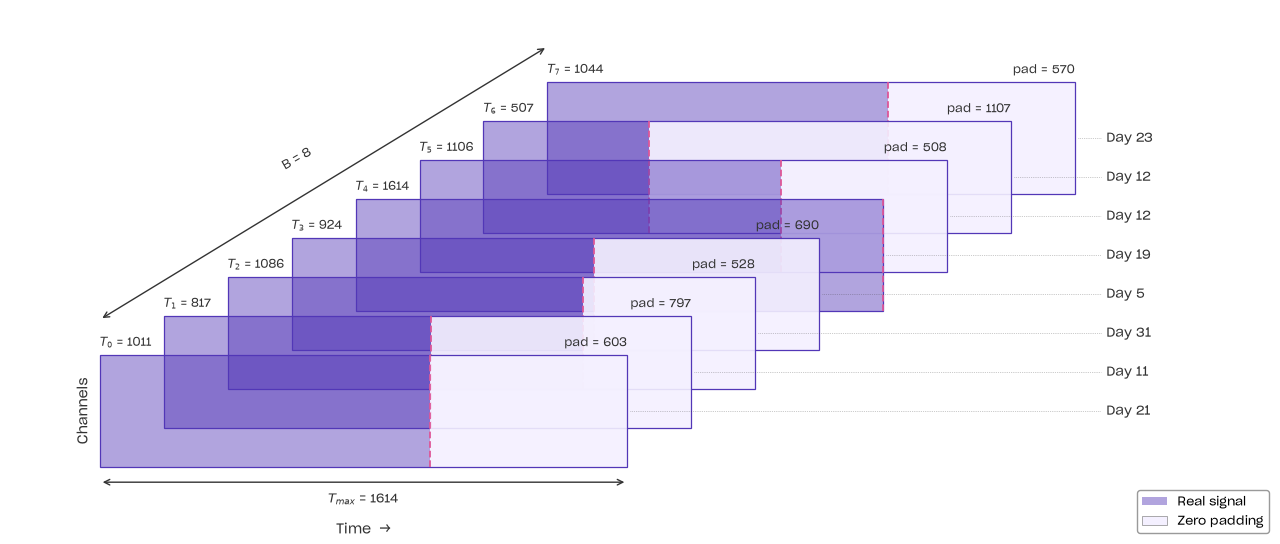

In [21]:
from brainwhisperer.data.batch import NeuralBatch

if loader is not None:
    batch = next(iter(loader))
else:
    # Synthetic fallback — varied lengths so padding is visible
    B, C, T_max_synth = 8, 512, 3000
    synth_lengths = torch.randint(800, T_max_synth, (B,))
    synth_signals = torch.zeros(B, C, T_max_synth)
    for i, L in enumerate(synth_lengths):
        synth_signals[i, :, :L] = torch.randn(C, L.item())
    batch = NeuralBatch(
        signals  = synth_signals,
        labels   = torch.randint(0, 200, (B, 10)),
        sbj_idx  = torch.zeros(B, dtype=torch.long),
        day_idx  = torch.randint(0, 20, (B,)),
        lengths  = synth_lengths,
    )

print('signals :', tuple(batch.signals.shape), batch.signals.dtype)
print('labels  :', tuple(batch.labels.shape))
print('sbj_idx :', batch.sbj_idx.tolist())
print('day_idx :', batch.day_idx.tolist())
print('lengths :', batch.lengths.tolist())

# ── parameters ────────────────────────────────────────────────────────────────
MAX_ROWS = 8   # how many sentences to draw (top N of the batch)
# ──────────────────────────────────────────────────────────────────────────────

from brainwhisperer.viz.data_pipeline import plot_batch_anatomy

with THEME:
    fig = plot_batch_anatomy(batch, max_rows=MAX_ROWS)
display(fig)

---
## 5. Signal augmentations

Side-by-side comparison of a raw signal and its augmented version. Note that augmentation is applied during training, here we call `transform_data` directly to show its effect.

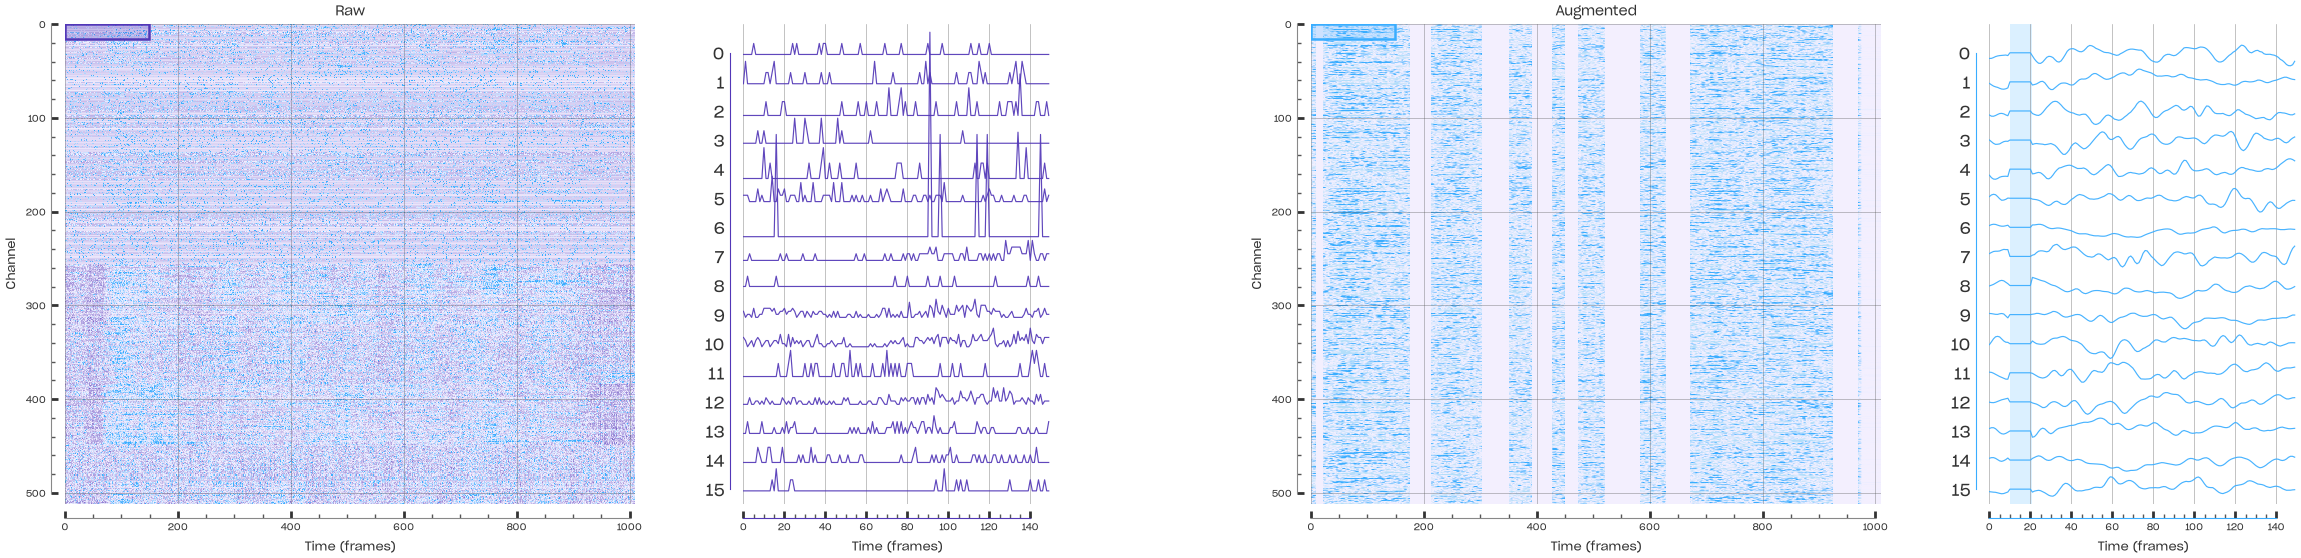

In [55]:
# ── parameters ────────────────────────────────────────────────────────────────
AUG_SAMPLE_IDX = 0          # which batch item to visualise
ZOOM_CHANNELS  = (0, 16)    # channel range for the zoom box
ZOOM_TIME      = (0, 150)   # time frame range for the zoom box
# ──────────────────────────────────────────────────────────────────────────────

from brainwhisperer.data.augmentations import transform_data
from brainwhisperer.viz.augmentations import plot_augmentation

raw          = batch.signals.clone()
augmented, _ = transform_data(batch.signals.clone(), batch.lengths.clone(), mode='train')

with THEME:
    fig = plot_augmentation(
        raw, augmented, batch.lengths,
        sample_idx    = AUG_SAMPLE_IDX,
        zoom_channels = ZOOM_CHANNELS,
        zoom_time     = ZOOM_TIME,
    )
display(fig)